# Hydraulic System — Model Training & Evaluation (CORRECTED)

This notebook trains separate component-condition classifiers from the processed hydraulic dataset.

**Key Corrections in this version:**
1. ✅ **3-Way Split Used:** Directly loads Train, Validation, and Test sets from Notebook 1.
2. ✅ **Added Baseline & XGBoost:** Includes `LogisticRegression` and `XGBClassifier` as per project plan.
3. ✅ **SHAP Analysis:** Replaces simple feature importance with SHAP to explain which sensors drive predictions.

The notebook uses the validation split to choose the best model and keeps the test set strictly for the final evaluation.

## 1. Install and import libraries

In [13]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib xgboost shap

In [14]:
import json
import shutil
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 2. Upload processed data (from Notebook 1)

In [15]:
from google.colab import files

REQUIRED_FILES = [
    "X_train_scaled.csv", "X_val_scaled.csv", "X_test_scaled.csv",
    "y_train.csv", "y_val.csv", "y_test.csv",
    "feature_columns.json",
]

DATA_DIR = Path("/content/hydraulic_processed")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Upload the ZIP or individual files
uploaded = files.upload()

for name in uploaded:
    source = Path("/content") / name
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(source) as archive:
            archive.extractall(DATA_DIR)
    else:
        shutil.copy2(source, DATA_DIR / Path(name).name)

def find_required_dir(root: Path) -> Path:
    direct = [root / name for name in REQUIRED_FILES]
    if all(path.exists() for path in direct):
        return root
    for candidate in root.rglob("feature_columns.json"):
        candidate_dir = candidate.parent
        if all((candidate_dir / name).exists() for name in REQUIRED_FILES):
            return candidate_dir
    return root

DATA_DIR = find_required_dir(DATA_DIR)
print("Using processed-data directory:", DATA_DIR)
print("Files:", sorted(path.name for path in DATA_DIR.iterdir()))

Saving processed_hydraulic.zip to processed_hydraulic (1).zip
Using processed-data directory: /content/hydraulic_processed
Files: ['X_test_scaled.csv', 'X_train_scaled.csv', 'X_val_scaled.csv', 'feature_columns.json', 'metadata.json', 'processed_hydraulic_features.csv', 'split_metadata.json', 'standard_scaler.joblib', 'test_cycle_ids.csv', 'train_cycle_ids.csv', 'training_medians.joblib', 'val_cycle_ids.csv', 'y_test.csv', 'y_train.csv', 'y_val.csv']


## 3. Load and validate the 3-way split data

In [16]:
targets = [
    "cooler_condition",
    "valve_condition",
    "pump_leakage",
    "accumulator_pressure",
]

missing = [name for name in REQUIRED_FILES if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError("Missing required processed files: " + ", ".join(missing))

# Load Features
X_train = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_val = pd.read_csv(DATA_DIR / "X_val_scaled.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_scaled.csv")

# Load Labels
y_train = pd.read_csv(DATA_DIR / "y_train.csv")
y_val = pd.read_csv(DATA_DIR / "y_val.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv")

with open(DATA_DIR / "feature_columns.json", "r", encoding="utf-8") as handle:
    feature_columns = json.load(handle)

assert list(X_train.columns) == feature_columns
assert list(X_val.columns) == feature_columns
assert list(X_test.columns) == feature_columns

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("All structural checks passed.")

Train: (1543, 85) | Val: (331, 85) | Test: (331, 85)
All structural checks passed.


In [17]:
# Normalize target labels
def normalize_target(series: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().all():
        return numeric.astype(int)
    return series.astype(str)

for target in targets:
    y_train[target] = normalize_target(y_train[target])
    y_val[target] = normalize_target(y_val[target])
    y_test[target] = normalize_target(y_test[target])

## 4. Define candidate models (Including Baseline & XGBoost)

In [18]:
def build_models():
    return {
        "LogisticRegression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "ExtraTrees": ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
        "XGBoost": XGBClassifier(
            n_estimators=300,
            learning_rate=0.08,
            max_depth=6,
            eval_metric="mlogloss",
            use_label_encoder=False,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    }

## 5. Train with Validation-based model selection

We use the **Validation set** (from Notebook 1) to choose the best model. The untouched **Test set** is used only for the final score.

In [19]:
from sklearn.preprocessing import LabelEncoder

validation_results = []
selected_model_names = {}

for target in targets:
    print("\n" + "=" * 70)
    print("VALIDATION TARGET:", target)
    print("=" * 70)

    y_fit = y_train[target]
    y_val_target = y_val[target]
    candidate_scores = []

    for model_name, model in build_models().items():
        print(f"Training {model_name} ...")

        # XGBoost requires labels to be 0, 1, ..., n_classes-1
        if model_name == "XGBoost":
            le = LabelEncoder()
            y_fit_enc = le.fit_transform(y_fit)
            model.fit(X_train, y_fit_enc)
            val_pred_enc = model.predict(X_val)
            val_pred = le.inverse_transform(val_pred_enc) # Decode back to original labels
        else:
            model.fit(X_train, y_fit)
            val_pred = model.predict(X_val)

        score = f1_score(y_val_target, val_pred, average="macro", zero_division=0)
        candidate_scores.append((score, model_name))

        validation_results.append({
            "target": target,
            "model": model_name,
            "validation_accuracy": accuracy_score(y_val_target, val_pred),
            "validation_balanced_accuracy": balanced_accuracy_score(y_val_target, val_pred),
            "validation_f1_macro": score,
        })
        print(f"  validation Macro F1: {score:.4f}")

    selected_model_names[target] = max(candidate_scores)[1]
    print(f"✅ Selected: {selected_model_names[target]}")


VALIDATION TARGET: cooler_condition
Training LogisticRegression ...
  validation Macro F1: 1.0000
Training RandomForest ...
  validation Macro F1: 1.0000
Training ExtraTrees ...
  validation Macro F1: 1.0000
Training HistGradientBoosting ...
  validation Macro F1: 1.0000
Training XGBoost ...
  validation Macro F1: 1.0000
✅ Selected: XGBoost

VALIDATION TARGET: valve_condition
Training LogisticRegression ...
  validation Macro F1: 0.8357
Training RandomForest ...
  validation Macro F1: 0.9813
Training ExtraTrees ...
  validation Macro F1: 0.9447
Training HistGradientBoosting ...
  validation Macro F1: 0.9824
Training XGBoost ...
  validation Macro F1: 0.9922
✅ Selected: XGBoost

VALIDATION TARGET: pump_leakage
Training LogisticRegression ...
  validation Macro F1: 0.9922
Training RandomForest ...
  validation Macro F1: 0.9971
Training ExtraTrees ...
  validation Macro F1: 0.9971
Training HistGradientBoosting ...
  validation Macro F1: 1.0000
Training XGBoost ...
  validation Macro F1: 

## 6. Final Evaluation on Test Data

In [20]:
final_results = []
best_models = {}
all_reports = {}
all_predictions = {}

for target in targets:
    model_name = selected_model_names[target]
    model = build_models()[model_name]

    # Retrain on full training data
    if model_name == "XGBoost":
        le = LabelEncoder()
        y_train_enc = le.fit_transform(y_train[target])
        model.fit(X_train, y_train_enc)
        pred_enc = model.predict(X_test)
        pred = le.inverse_transform(pred_enc) # Decode back to original labels
    else:
        model.fit(X_train, y_train[target])
        pred = model.predict(X_test)

    best_models[target] = model
    all_predictions[target] = pred
    all_reports[target] = classification_report(y_test[target], pred, zero_division=0)

    final_results.append({
        "target": target,
        "selected_model": model_name,
        "test_accuracy": accuracy_score(y_test[target], pred),
        "test_balanced_accuracy": balanced_accuracy_score(y_test[target], pred),
        "test_precision_macro": precision_score(y_test[target], pred, average="macro", zero_division=0),
        "test_recall_macro": recall_score(y_test[target], pred, average="macro", zero_division=0),
        "test_f1_macro": f1_score(y_test[target], pred, average="macro", zero_division=0),
        "test_f1_weighted": f1_score(y_test[target], pred, average="weighted", zero_division=0),
    })
    print(f"{target}: {model_name} | test Macro F1={final_results[-1]['test_f1_macro']:.4f}")

validation_df = pd.DataFrame(validation_results).sort_values(["target", "validation_f1_macro"], ascending=[True, False])
results_df = pd.DataFrame(final_results)

print("\n--- Validation Results (All Models) ---")
display(validation_df.round(4))
print("\n--- Final Test Results (Best Models) ---")
display(results_df.round(4))

cooler_condition: XGBoost | test Macro F1=0.9970
valve_condition: XGBoost | test Macro F1=0.9847
pump_leakage: XGBoost | test Macro F1=0.9925
accumulator_pressure: RandomForest | test Macro F1=0.9811

--- Validation Results (All Models) ---


,target,model,validation_accuracy,validation_balanced_accuracy,validation_f1_macro
16,accumulator_pressure,RandomForest,0.9970,0.9954,0.9956
18,accumulator_pressure,HistGradientBoosting,0.9940,0.9934,0.9923
19,accumulator_pressure,XGBoost,0.9909,0.9914,0.9890
17,accumulator_pressure,ExtraTrees,0.9879,0.9845,0.9837
15,accumulator_pressure,LogisticRegression,0.8943,0.8869,0.8762
0,cooler_condition,LogisticRegression,1.0000,1.0000,1.0000
1,cooler_condition,RandomForest,1.0000,1.0000,1.0000
2,cooler_condition,ExtraTrees,1.0000,1.0000,1.0000
3,cooler_condition,HistGradientBoosting,1.0000,1.0000,1.0000
4,cooler_condition,XGBoost,1.0000,1.0000,1.0000



--- Final Test Results (Best Models) ---


,target,selected_model,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted
0,cooler_condition,XGBoost,0.9970,0.9970,0.9970,0.9970,0.9970,0.9970
1,valve_condition,XGBoost,0.9849,0.9830,0.9866,0.9830,0.9847,0.9848
2,pump_leakage,XGBoost,0.9940,0.9944,0.9906,0.9944,0.9925,0.9940
3,accumulator_pressure,RandomForest,0.9849,0.9826,0.9797,0.9826,0.9811,0.9849


## 7. Confusion Matrices


cooler_condition — XGBoost
              precision    recall  f1-score   support

           3       0.99      1.00      1.00       110
          20       1.00      0.99      1.00       110
         100       1.00      1.00      1.00       111

    accuracy                           1.00       331
   macro avg       1.00      1.00      1.00       331
weighted avg       1.00      1.00      1.00       331



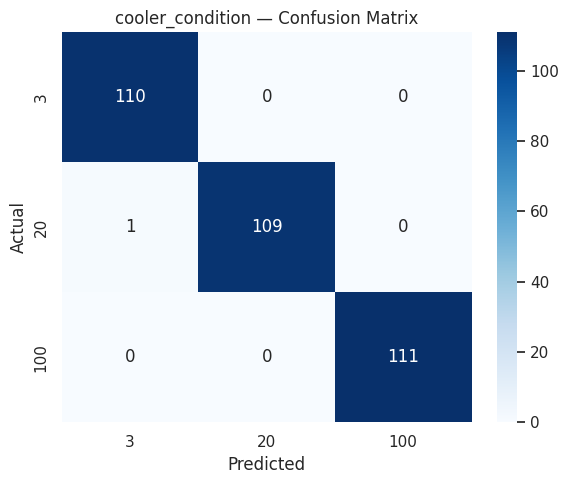


valve_condition — XGBoost
              precision    recall  f1-score   support

          73       1.00      1.00      1.00        55
          80       0.98      1.00      0.99        62
          90       0.98      0.94      0.96        54
         100       0.98      0.99      0.98       160

    accuracy                           0.98       331
   macro avg       0.99      0.98      0.98       331
weighted avg       0.98      0.98      0.98       331



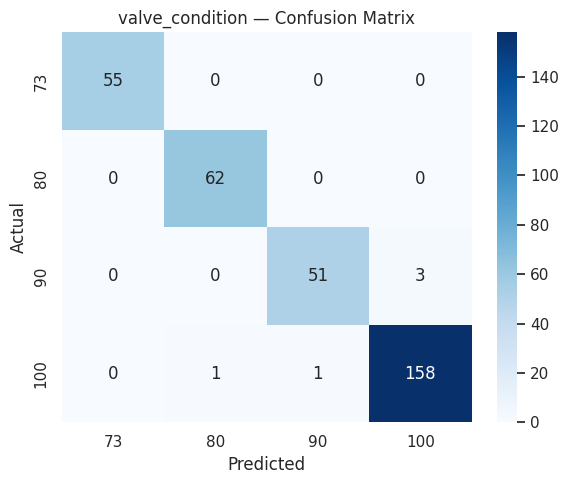


pump_leakage — XGBoost
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       185
           1       0.99      0.99      0.99        88
           2       0.98      1.00      0.99        58

    accuracy                           0.99       331
   macro avg       0.99      0.99      0.99       331
weighted avg       0.99      0.99      0.99       331



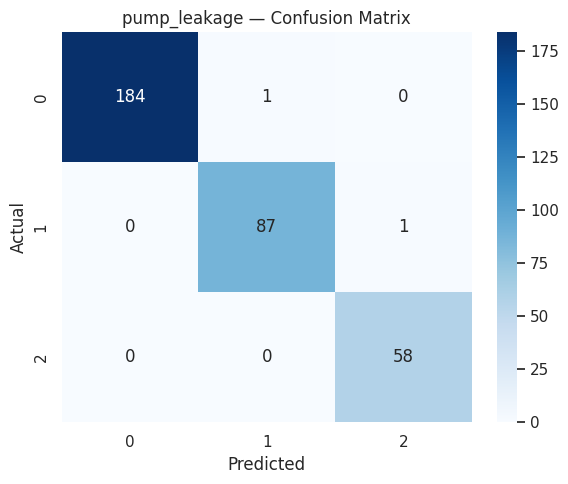


accumulator_pressure — RandomForest
              precision    recall  f1-score   support

          90       1.00      0.99      1.00       120
         100       0.97      0.96      0.96        69
         115       0.95      0.98      0.96        56
         130       1.00      1.00      1.00        86

    accuracy                           0.98       331
   macro avg       0.98      0.98      0.98       331
weighted avg       0.99      0.98      0.98       331



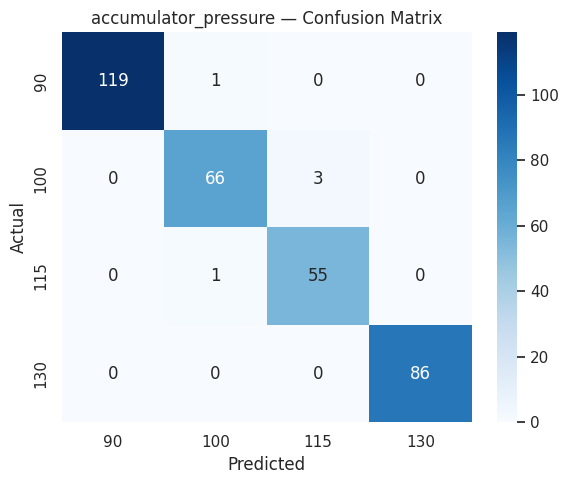

In [21]:
for target in targets:
    pred = all_predictions[target]
    labels = sorted(pd.unique(pd.concat([y_train[target], y_test[target]])))

    print("\n" + "=" * 70)
    print(f"{target} — {selected_model_names[target]}")
    print(all_reports[target])

    cm = confusion_matrix(y_test[target], pred, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(f"{target} — Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

## 8. SHAP Analysis (Explainable AI)

Using SHAP to see which sensors each model uses. This replaces the basic `feature_importances_`.


SHAP Analysis for: cooler_condition (Model: XGBoost)


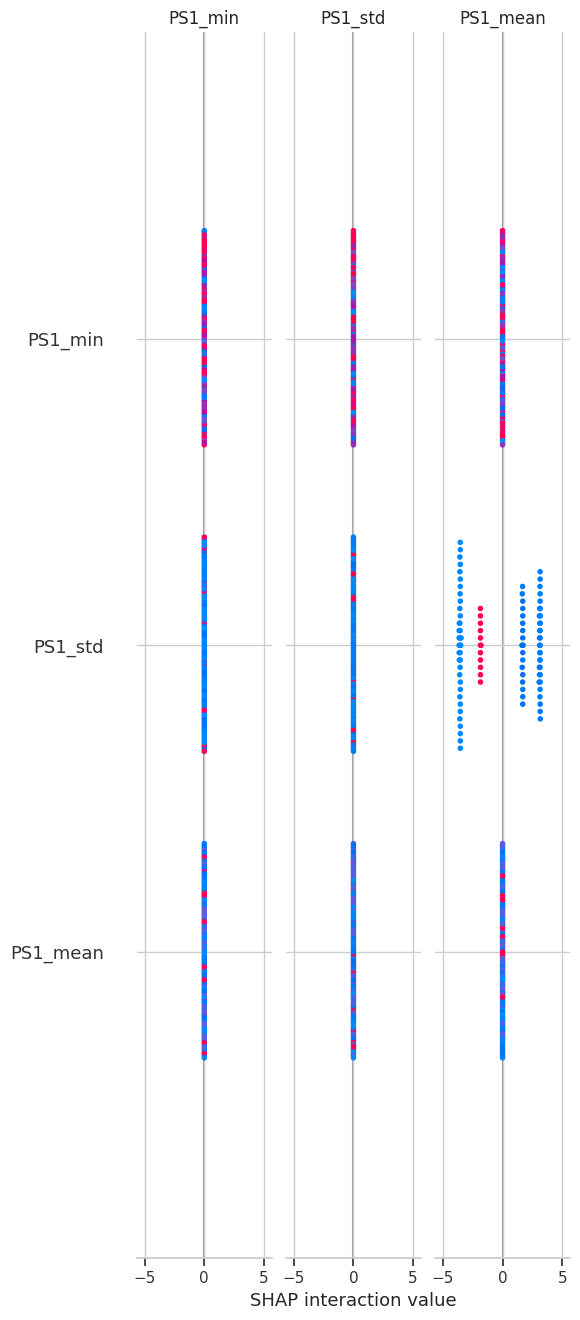


SHAP Analysis for: valve_condition (Model: XGBoost)


 94%|=================== | 377/400 [00:14<00:00]       

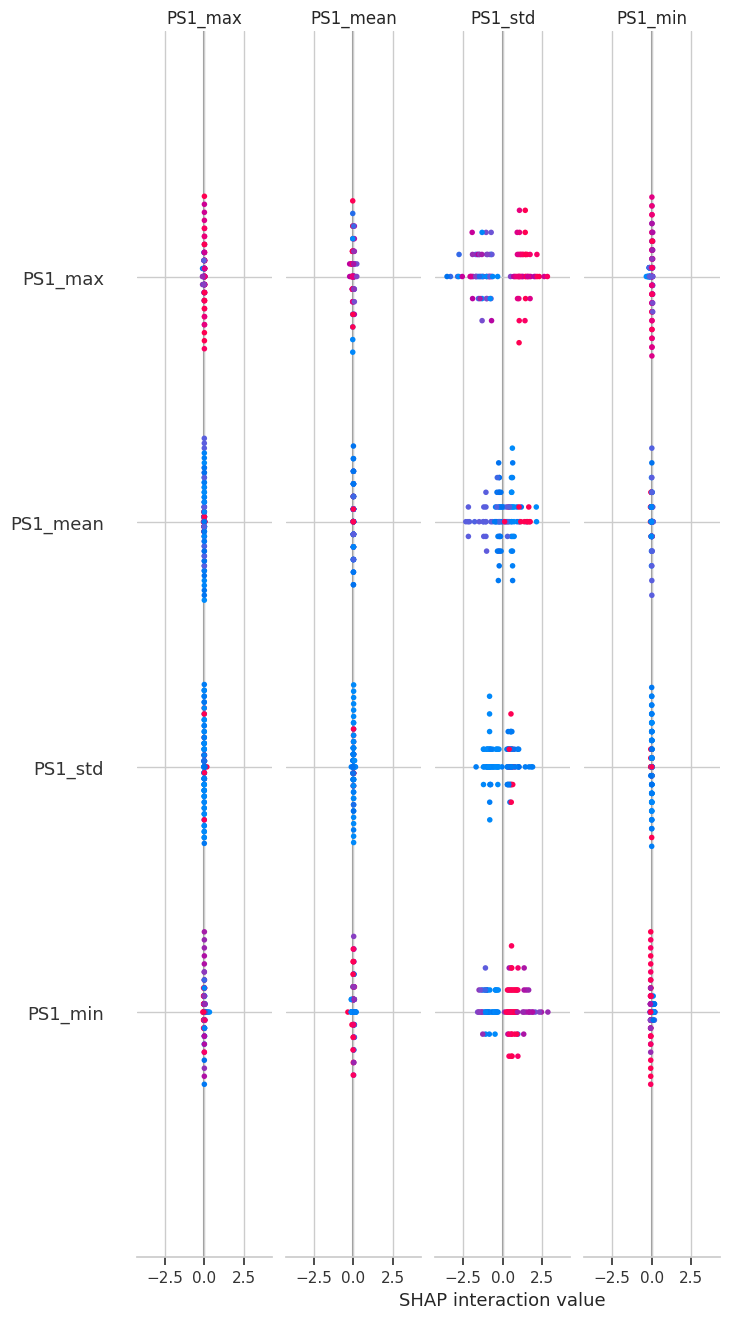


SHAP Analysis for: pump_leakage (Model: XGBoost)


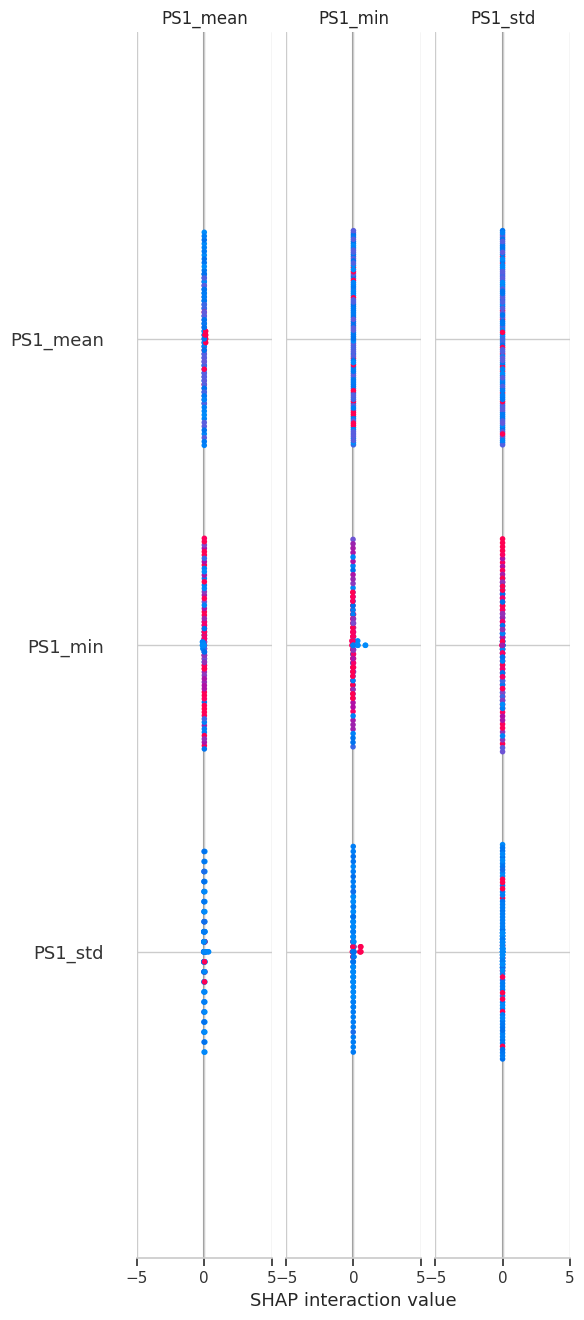


SHAP Analysis for: accumulator_pressure (Model: RandomForest)


100%|===================| 399/400 [00:19<00:00]       

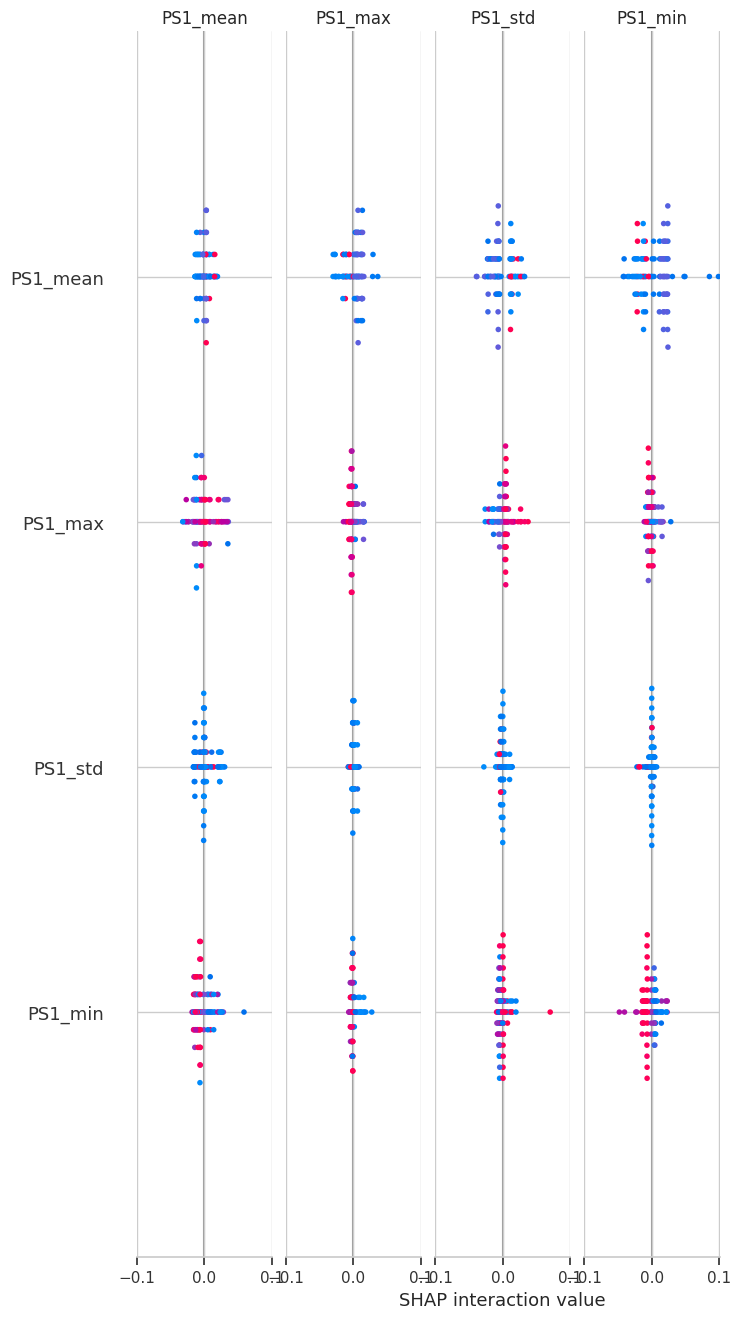

In [22]:
# Use a background sample of training data to speed up SHAP calculation
background_data = shap.sample(X_train, 100)
test_sample = shap.sample(X_test, 100)

for target, model in best_models.items():
    print(f"\n{'='*60}")
    print(f"SHAP Analysis for: {target} (Model: {selected_model_names[target]})")
    print(f"{'='*60}")

    try:
        # Choose the right explainer based on model type
        if isinstance(model, LogisticRegression):
            explainer = shap.LinearExplainer(model, background_data)
        else:
            explainer = shap.TreeExplainer(model, background_data)

        shap_values = explainer.shap_values(test_sample)

        # For multiclass models, shap_values is a list of arrays (one per class)
        if isinstance(shap_values, list):
            # Calculate mean absolute SHAP value across all classes to find overall important features
            mean_abs_shap = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
            top_indices = np.argsort(mean_abs_shap)[-15:][::-1]
            top_features = [feature_columns[i] for i in top_indices]

            plt.figure(figsize=(10, 6))
            plt.barh(top_features, mean_abs_shap[top_indices], color="#1769aa")
            plt.title(f"Top 15 Features (Mean |SHAP| across all classes) — {target}")
            plt.xlabel("Mean |SHAP value|")
            plt.tight_layout()
            plt.show()
        else:
            # For binary or regression
            shap.summary_plot(shap_values, test_sample, feature_names=feature_columns, max_display=15)

    except Exception as e:
        print(f"Could not compute SHAP values for {target}: {e}")

## 9. Export trained models and metadata

In [23]:
EXPORT_DIR = Path("/content/hydraulic_trained_models")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

for target, model in best_models.items():
    joblib.dump(model, EXPORT_DIR / f"{target}_model.joblib")

with open(EXPORT_DIR / "feature_columns.json", "w", encoding="utf-8") as handle:
    json.dump(feature_columns, handle, indent=2)

scaler_path = DATA_DIR / "standard_scaler.joblib"
if scaler_path.exists():
    shutil.copy2(scaler_path, EXPORT_DIR / "standard_scaler.joblib")
else:
    print("WARNING: standard_scaler.joblib was not uploaded.")

validation_df.to_csv(EXPORT_DIR / "validation_model_selection.csv", index=False)
results_df.to_csv(EXPORT_DIR / "final_test_results.csv", index=False)

metadata = {
    "project": "Hydraulic Component Condition Classification",
    "targets": targets,
    "n_features": len(feature_columns),
    "selected_models": selected_model_names,
    "random_state": RANDOM_STATE,
    "input_expected": "features in feature_columns.json order; use the original fitted scaler for raw feature inputs",
    "limitation": "Component condition classification only; not future failure prediction or RUL.",
}
with open(EXPORT_DIR / "model_metadata.json", "w", encoding="utf-8") as handle:
    json.dump(metadata, handle, indent=2)

zip_path = shutil.make_archive("/content/hydraulic_trained_models", "zip", EXPORT_DIR)
print("Export ready:", zip_path)
print("Files:", sorted(path.name for path in EXPORT_DIR.iterdir()))

Export ready: /content/hydraulic_trained_models.zip
Files: ['accumulator_pressure_model.joblib', 'cooler_condition_model.joblib', 'feature_columns.json', 'final_test_results.csv', 'model_metadata.json', 'pump_leakage_model.joblib', 'standard_scaler.joblib', 'validation_model_selection.csv', 'valve_condition_model.joblib']


## 10. Download the model package

Download the generated ZIP from the Colab file panel. It contains the trained models, feature order, and metrics.

In [25]:
import shutil
zip_path = shutil.make_archive("/content/hydraulic_trained_models", "zip", EXPORT_DIR)
print(f"Download ready: {zip_path}")
files.download(zip_path)

Download ready: /content/hydraulic_trained_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>